<a href="https://colab.research.google.com/github/KwancheolShin/introduction-to-deep-learning/blob/main/multiclass_mnist/mnist_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST 다중분류: PyTorch

같은 network를 PyTorch로 만든다 (`nn.Module`, `CrossEntropyLoss`, `SGD`, `DataLoader`). 원본: `mnist_torch.py`

* 셀을 위에서부터 차례로 실행한다 (Shift+Enter). 앞 셀에서 만든 변수는 다음 셀에서 그대로 쓸 수 있다.
* Colab에서 GPU를 쓰려면 메뉴의 **런타임 → 런타임 유형 변경 → GPU**를 고른다. CPU에서도 동작한다.
* 그림은 작업 폴더의 `figures/`에도 저장된다 (Colab의 작업 폴더는 `/content`이며, 세션이 끝나면 지워진다).


## 0. Setup

In [1]:
# MNIST classification with PyTorch: a fully connected network
# Run this file from its own folder; figures are saved to ./figures/*.png
#   Cells: each '# %%' starts a cell. In VS Code, Run Cell (Shift+Enter) sends one cell to the
#   Interactive window (variables stay in the kernel); 'python <file>' still runs the whole file.

import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.datasets import fetch_openml

torch.manual_seed(0)
os.makedirs("figures", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device}")

Using cuda


## 1. Data

In [2]:
# ----------------------------------------------------
# Data
# ----------------------------------------------------
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
X = torch.tensor(X / 255.0, dtype=torch.float32)   # (70000, 784)
y = torch.tensor(y.astype(np.int64))               # (70000,)

train_val = TensorDataset(X[:60000], y[:60000])
test_set  = TensorDataset(X[60000:], y[60000:])
train_set, val_set = random_split(train_val, [55000, 5000])

batch_size = 100
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=1000)
test_loader  = DataLoader(test_set, batch_size=1000)

## 2. Model, loss, optimizer (re-run this cell to start training from scratch)

In [3]:
# ----------------------------------------------------
# Model
# ----------------------------------------------------
class MLP(nn.Module):
    def __init__(self, in_features=784, hidden=(100,), num_classes=10):
        super().__init__()
        layers = []
        for h in hidden:
            layers += [nn.Linear(in_features, h), nn.ReLU()]
            in_features = h
        layers.append(nn.Linear(in_features, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)          # logits

model = MLP(hidden=(100,)).to(device)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

# model = nn.Sequential(
#     nn.Linear(784, 100),    # (N, 784) -> (N, 100)
#     nn.ReLU(),
#     nn.Linear(100, 10),     # (N, 100) -> (N, 10), logits
# ).to(device)


loss_fn   = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)
number of parameters: 79510


## 3. Training and evaluation functions

In [4]:
# ----------------------------------------------------
# Training / evaluation
# ----------------------------------------------------
def train_one_epoch(model, loader):
    model.train()
    losses = []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        logits = model(xb)
        loss = loss_fn(logits, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
    return losses


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        pred = model(xb).argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += yb.numel()
    return correct / total

## 4. Training (takes a while)

In [5]:
epochs = 10
loss_history, val_acc_history = [], []
for epoch in range(1, epochs + 1):
    loss_history += train_one_epoch(model, train_loader)
    val_acc = evaluate(model, val_loader)
    val_acc_history.append(val_acc)
    print(f"epoch {epoch:2d} | loss {loss_history[-1]:.4f} | val acc {val_acc:.4f}")

epoch  1 | loss 0.3039 | val acc 0.9126


epoch  2 | loss 0.1828 | val acc 0.9298


epoch  3 | loss 0.1847 | val acc 0.9400


epoch  4 | loss 0.1535 | val acc 0.9470


epoch  5 | loss 0.1377 | val acc 0.9486


epoch  6 | loss 0.1828 | val acc 0.9570


epoch  7 | loss 0.1305 | val acc 0.9594


epoch  8 | loss 0.1273 | val acc 0.9626


epoch  9 | loss 0.1139 | val acc 0.9642


epoch 10 | loss 0.0702 | val acc 0.9644


## 5. Test accuracy: ONCE, at the end

In [6]:
test_acc = evaluate(model, test_loader)
print(f"test accuracy: {test_acc:.4f}")

test accuracy: 0.9696


## 6. Plots

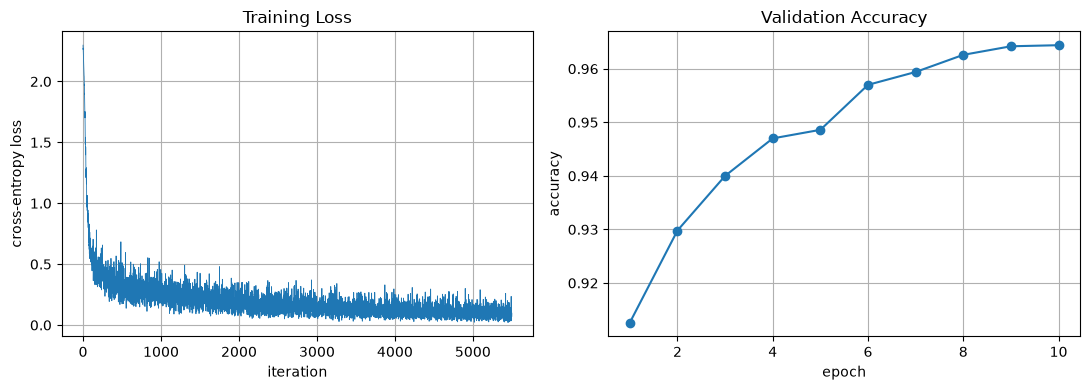

In [7]:
# ----------------------------------------------------
# Plots
# ----------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(loss_history, linewidth=0.6)
ax[0].set(xlabel="iteration", ylabel="cross-entropy loss", title="Training Loss")
ax[0].grid(True)
ax[1].plot(range(1, epochs + 1), val_acc_history, "o-")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Validation Accuracy")
ax[1].grid(True)
fig.tight_layout()
fig.savefig("figures/torch_loss_acc.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Predictions on the first 10 test images

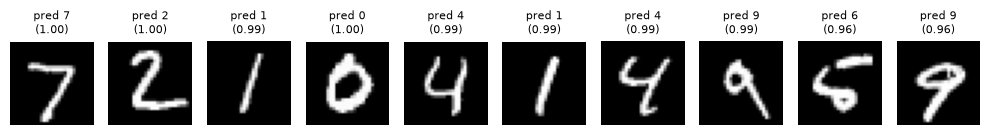

In [8]:
# predictions on the first 10 test images
model.eval()
with torch.no_grad():
    xb, yb = next(iter(test_loader))
    probs = torch.softmax(model(xb.to(device)), dim=1).cpu()
pred = probs.argmax(dim=1)

fig, axes = plt.subplots(1, 10, figsize=(10, 2.6))
for k, a in enumerate(axes):
    a.imshow(xb[k].reshape(28, 28), cmap="gray")
    a.set_title(f"pred {pred[k].item()}\n({probs[k, pred[k]]:.2f})", fontsize=8)
    a.axis("off")
fig.tight_layout()
fig.savefig("figures/torch_predictions.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Save the trained weights

In [9]:
# save the trained weights
torch.save(model.state_dict(), "mnist_mlp.pt")